# Comparative Machine Learning for Heart Disease Detection

This practical study develops and evaluates six supervised machine-learning classifiers for heart disease detection using a common clinical dataset. A reproducible preprocessing, validation and evaluation framework is applied so that algorithmic performance can be compared under consistent experimental conditions.

## Python Environment and Libraries

Python is used as the implementation environment because it provides established libraries for clinical data analysis and supervised learning. Pandas and NumPy support data preparation, scikit-learn provides reproducible modelling pipelines, while Matplotlib and Seaborn support graphical evaluation.

In [1]:
# Core libraries for reproducibility, numerical operations and data handling
import warnings
warnings.filterwarnings("ignore")

import time
import random
import numpy as np
import pandas as pd

# Visualisation libraries for exploratory analysis and model evaluation
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading from the Hugging Face repository
from datasets import load_dataset

# Data splitting and cross-validation for robust model assessment
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

# Pipeline construction and preprocessing of mixed feature types
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

# Handling missing observations before model training
from sklearn.impute import SimpleImputer

# Classification algorithms used for comparative modelling
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Gradient-boosting model for non-linear classification patterns
from xgboost import XGBClassifier

# Evaluation metrics for classification performance and model comparison
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

# Assessing the contribution of individual features to model predictions
from sklearn.inspection import permutation_importance

## Reproducibility Configuration

A fixed random seed is established to reduce variation caused by stochastic operations. Reproducibility is important because the thesis compares algorithms experimentally, meaning that changes in data splitting or model randomness should not unintentionally influence comparative conclusions.

In [2]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print(f"Random state: {RANDOM_STATE}")

Random state: 42


## Dataset Acquisition

The study uses the publicly available heart-disease dataset hosted on Hugging Face. The dataset contains demographic and clinical predictors together with a binary target indicating the presence or absence of heart disease, providing the basis for supervised classification.

In [3]:
# Define the dataset repository used for the empirical analysis
DATASET_NAME = "marianeft/heart-diease-dataset"

# Load the dataset directly from the Hugging Face repository
ds = load_dataset(DATASET_NAME)

# Confirm the available dataset splits and basic structure
print(ds)

README.md:   0%|          | 0.00/31.0 [00:00<?, ?B/s]

heart.csv:   0%|          | 0.00/38.1k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1025 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
        num_rows: 1025
    })
})


## Dataset Structure

The dataset object is inspected before conversion so that the available split structure can be identified. This prevents assumptions about whether the source provides a single dataset or predefined training and testing partitions, supporting transparent and reproducible data handling.

In [4]:
# Identify the returned dataset object and its available data splits
print("Dataset type:", type(ds))

if hasattr(ds, "keys"):
    # Report the available splits for subsequent data preparation
    print("Available splits:", list(ds.keys()))
else:
    # Handle datasets provided as a single dataset object
    print("Single dataset object detected.")

Dataset type: <class 'datasets.dataset_dict.DatasetDict'>
Available splits: ['train']


In [5]:
# Convert the dataset to a pandas DataFrame.

if hasattr(ds, "keys"):
    first_split = list(ds.keys())[0]
    df = ds[first_split].to_pandas()
    print(f"Using split for initial inspection: {first_split}")
else:
    df = ds.to_pandas()

print("Dataset shape:", df.shape)
df.head()

Using split for initial inspection: train
Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## Variable Inspection

The dataset variables are examined to confirm their names, data types and measurement structure. This step establishes the distinction between continuous clinical measurements, categorical clinical attributes and the binary target before preprocessing and model development.

In [6]:
# Inspect the available variables and their stored data types
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:


,Data Type
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


In [7]:
print(f"Number of observations: {df.shape[0]}")
print(f"Number of variables: {df.shape[1]}")
print(f"Number of predictors: {df.shape[1] - 1}")

Number of observations: 1025
Number of variables: 14
Number of predictors: 13


In [8]:
display(df.head())
display(df.tail())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


## Missing-Value Assessment

Missing values are assessed for every variable before modelling. The analysis distinguishes between variables with complete observations and those requiring imputation. Imputation, where necessary, will be performed inside the modelling pipeline to prevent information from the test data entering training.

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percentage
age,0,0.0
sex,0,0.0
cp,0,0.0
trestbps,0,0.0
chol,0,0.0
fbs,0,0.0
restecg,0,0.0
thalach,0,0.0
exang,0,0.0
oldpeak,0,0.0


## Categorical Value Inspection

Unique values are examined to identify categorical coding, unexpected categories and potential data-quality problems. This is particularly important for variables such as chest-pain type, resting ECG, slope, number of vessels and thalassemia coding.

In [11]:
for column in df.columns:
    print(f"\n{column}")
    print(df[column].unique()[:20])


age
[52 53 70 61 62 58 55 46 54 71 43 34 51 50 60 67 45 63 42 44]

sex
[1 0]

cp
[0 1 2 3]

trestbps
[125 140 145 148 138 100 114 160 120 122 112 132 118 128 124 106 104 135
 130 136]

chol
[212 203 174 294 248 318 289 249 286 149 341 210 298 204 308 266 244 211
 185 223]

fbs
[0 1]

restecg
[1 0 2]

thalach
[168 155 125 161 106 122 140 145 144 116 136 192 156 142 109 162 165 148
 172 173]

exang
[0 1]

oldpeak
[1.  3.1 2.6 0.  1.9 4.4 0.8 3.2 1.6 3.  0.7 4.2 1.5 2.2 1.1 0.3 0.4 0.6
 3.4 2.8]

slope
[2 0 1]

ca
[2 0 1 3 4]

thal
[3 2 1 0]

target
[0 1]


##  Descriptive Statistics

Descriptive statistics provide an initial understanding of the distribution and scale of the clinical variables. Means, standard deviations, quartiles and ranges are examined before preprocessing so that potentially unusual observations and differences in measurement scales can be identified.

In [12]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


##  Target-Class Distribution

The target variable is examined to determine whether the dataset contains balanced or imbalanced classes. Class distribution is important in medical classification because accuracy alone may provide an incomplete representation of performance when disease and non-disease observations occur at different frequencies.

In [13]:
# Summarise the distribution of the target classes for the classification task
target_counts = df["target"].value_counts().sort_index()
target_percentages = df["target"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

# Display class frequencies to assess potential class imbalance
display(target_summary)

,Count,Percentage
target,,
0,499,48.68
1,526,51.32


## Predictor Classification

The predictors are separated according to their measurement characteristics. Continuous variables require scaling for distance- and margin-based algorithms, whereas categorical variables require encoding. Keeping these transformations within a pipeline ensures identical processing without test-data leakage.

In [14]:
# Define predictor groups according to their measurement and coding structure
numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

# Specify the outcome variable used for binary classification
target_column = "target"

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [15]:
expected_columns = numeric_features + categorical_features + [target_column]

missing_expected = set(expected_columns) - set(df.columns)
unexpected_columns = set(df.columns) - set(expected_columns)

print("Missing expected columns:", missing_expected)
print("Unexpected columns:", unexpected_columns)

Missing expected columns: set()
Unexpected columns: set()


## Outlier Investigation

Potential outliers are identified using the interquartile-range rule rather than automatically deleted. Extreme clinical observations may represent genuine patients rather than errors, so observations are retained unless evidence demonstrates that values are invalid or incorrectly recorded.

In [16]:
# Identify potential outliers in the continuous clinical variables using the IQR rule
outlier_results = []

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count observations falling outside the expected IQR range
    count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_results.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": count,
        "Percentage": (count / len(df)) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

# Present the screening results for data-quality assessment
display(outlier_df.round(2))

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Percentage
0,age,48.0,61.0,13.0,28.5,80.5,0,0.00
1,trestbps,120.0,140.0,20.0,90.0,170.0,30,2.93
2,chol,211.0,275.0,64.0,115.0,371.0,16,1.56
3,thalach,132.0,166.0,34.0,81.0,217.0,4,0.39
4,oldpeak,0.0,1.8,1.8,-2.7,4.5,7,0.68


## Distribution of Numerical Variables

The distributions of continuous clinical measurements are visualised to identify skewness, concentration and extreme observations. This provides descriptive evidence for preprocessing decisions while avoiding unsupported removal of clinically plausible values.

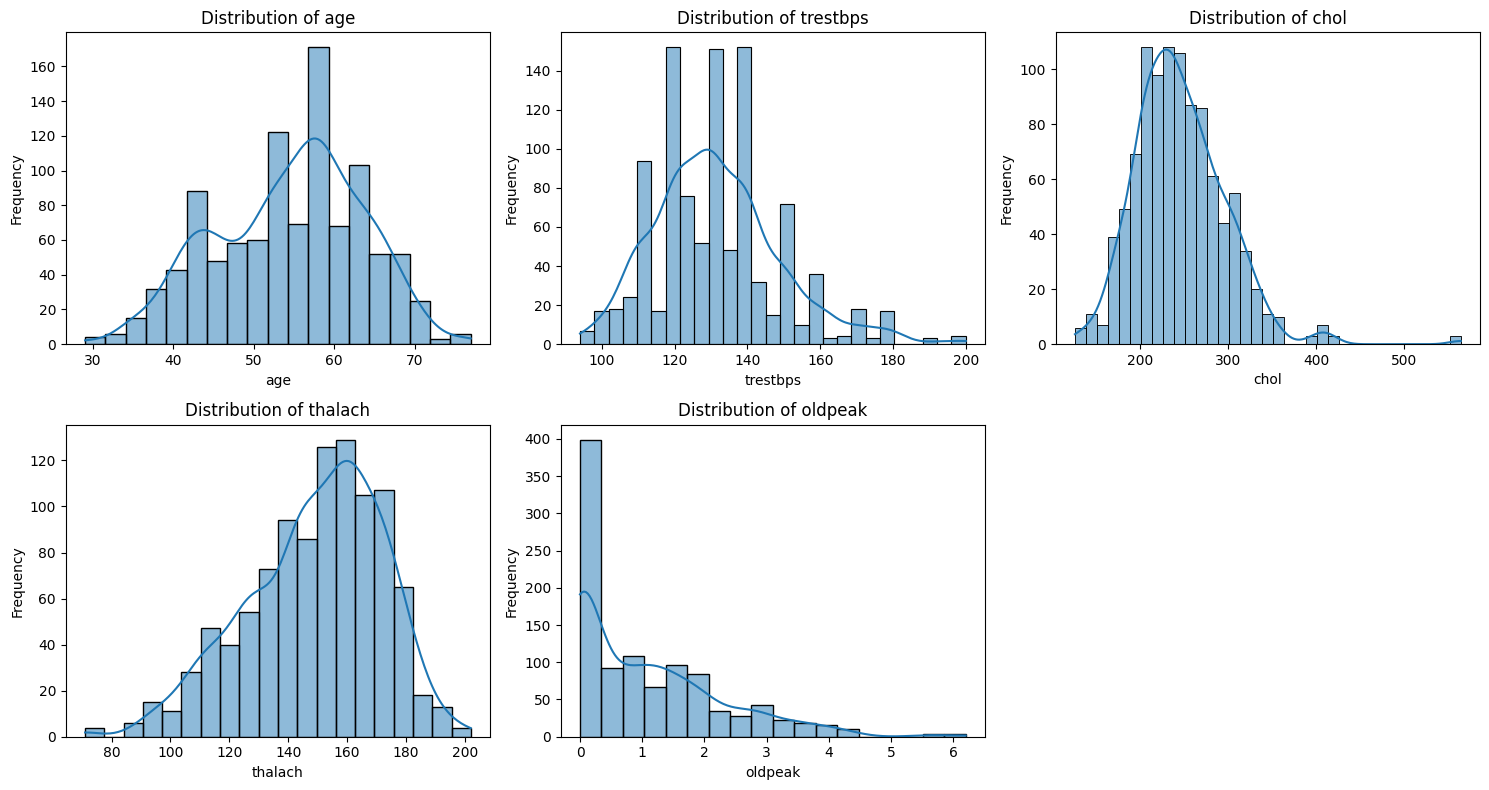

In [18]:
# Compare the distributions of all continuous variables within one figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 8)
)

axes = axes.flatten()

for i, column in enumerate(numeric_features):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Remove the unused subplot because five variables are being analysed
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

## Feature Relationship Analysis

Correlation analysis is used as an exploratory diagnostic rather than as evidence of causation. It helps identify relationships among numerical variables and potential redundancy, while model development remains based on the predefined feature set rather than exploratory correlations alone.

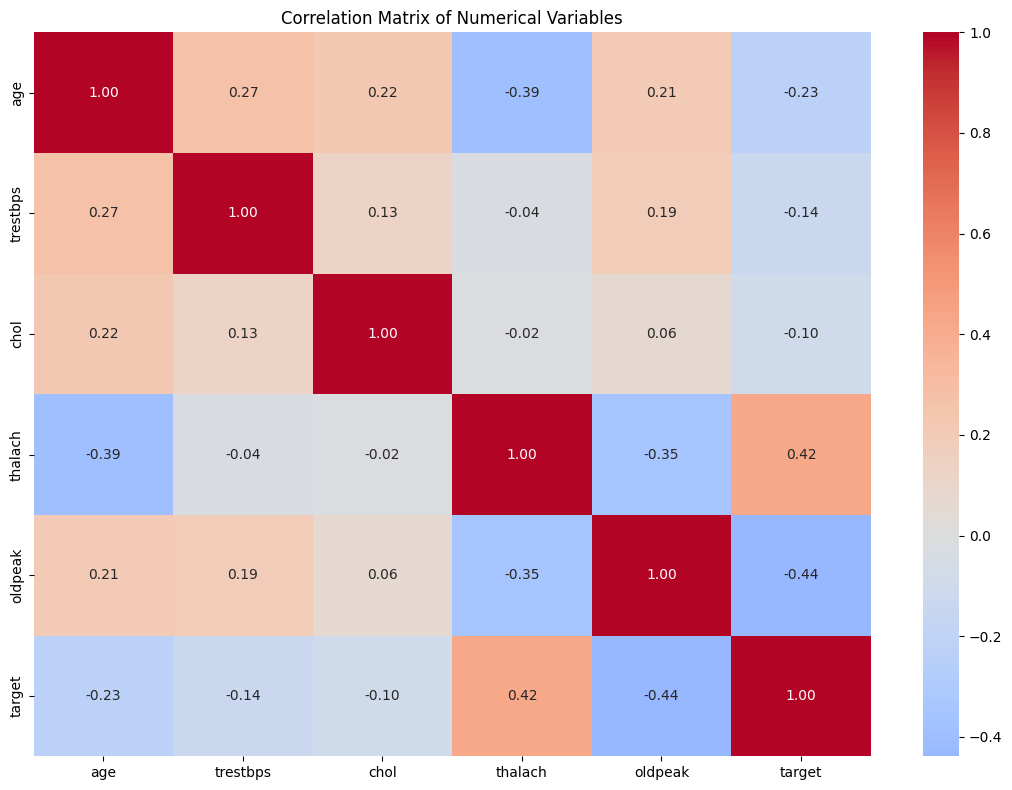

In [19]:
# Examine linear relationships between numerical predictors and the target variable
plt.figure(figsize=(11, 8))

correlation_matrix = df[numeric_features + [target_column]].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

##  Numerical Features by Disease Status

Numerical predictors are compared across target classes to identify descriptive differences between observations with and without the recorded heart-disease outcome. These comparisons are exploratory and are not interpreted as evidence that individual variables causally produce disease.

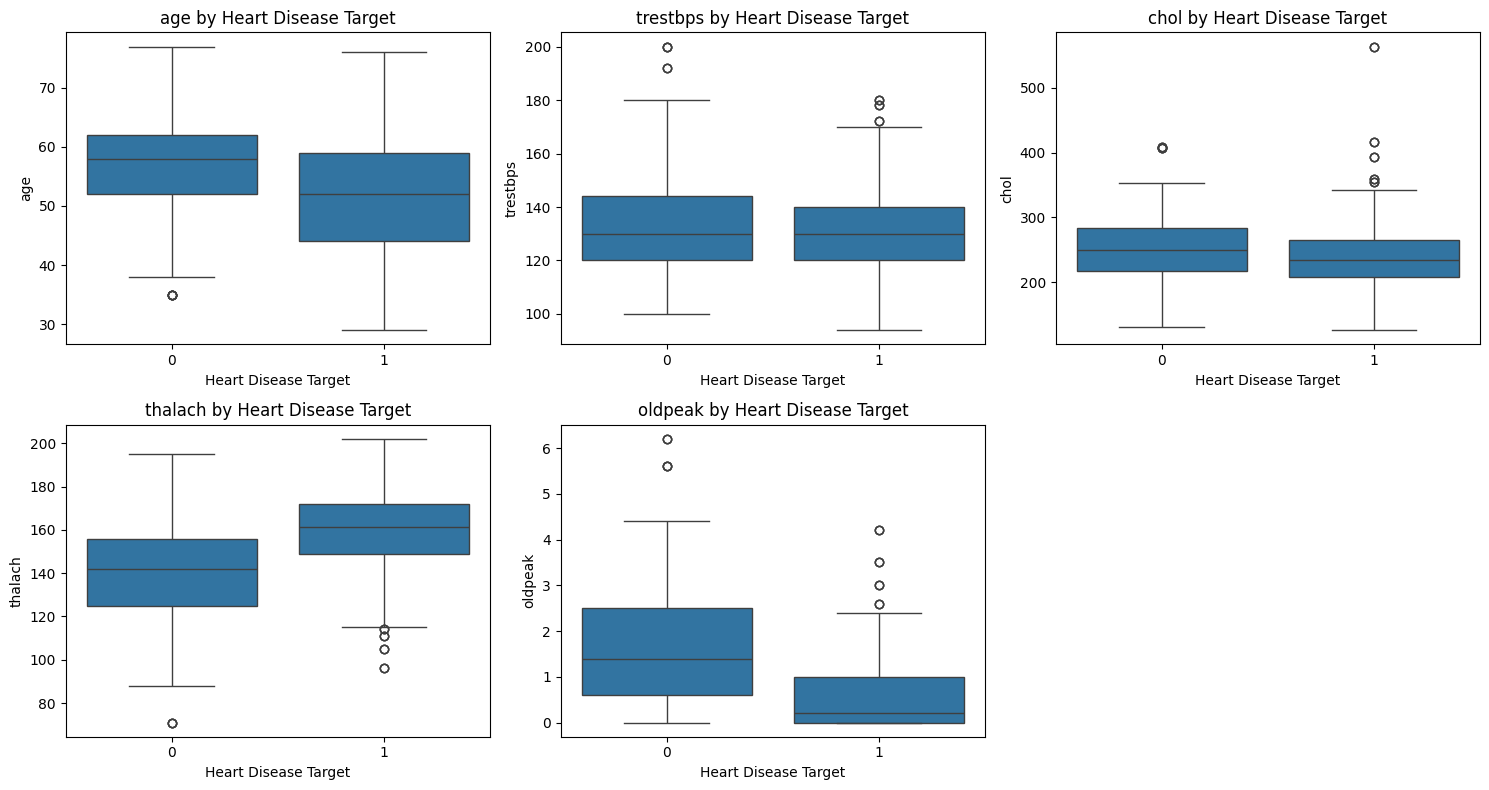

In [20]:
# Compare numerical feature distributions across the two target classes
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 8)
)

axes = axes.flatten()

for i, column in enumerate(numeric_features):
    sns.boxplot(
        data=df,
        x="target",
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} by Heart Disease Target")
    axes[i].set_xlabel("Heart Disease Target")
    axes[i].set_ylabel(column)

# Remove the unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

## Feature and Target Separation

The target variable is separated from the predictor matrix before model development. No target-derived information is included among the predictors. This separation establishes the supervised classification structure required by all six selected machine-learning algorithms.

In [21]:
# Separate predictor variables from the target used for classification
X = df.drop(columns=[target_column])
y = df[target_column]

# Confirm the dimensions of the modelling inputs before data splitting
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Verify the distinct classes represented in the target variable
print("\nTarget values:")
print(sorted(y.unique()))

Feature matrix shape: (1025, 13)
Target vector shape: (1025,)

Target values:
[np.int64(0), np.int64(1)]


## Stratified Train-Test Split

The dataset is divided into training and independent testing subsets using stratification. The procedure preserves the target-class proportions across both subsets, while the test data remains unseen during preprocessing, hyperparameter optimisation and model selection.

In [22]:
# Split the data into training and testing sets using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Report the observations available for model development and evaluation
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Verify that class proportions are retained across both subsets
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training observations: 820
Testing observations: 205

Training class proportions:
target
0    0.486585
1    0.513415
Name: proportion, dtype: float64

Testing class proportions:
target
0    0.487805
1    0.512195
Name: proportion, dtype: float64


# Preprocessing Pipeline

## Leakage-Controlled Preprocessing

Preprocessing is implemented through a scikit-learn pipeline so transformations are learned only from training data. Numerical variables are imputed and standardised, while categorical variables are imputed and one-hot encoded. The same controlled procedure is applied during validation and testing.

In [23]:
# Build separate preprocessing steps for numerical and categorical predictors
numeric_transformer = Pipeline(
    steps=[
        # Replace missing numerical values with the median of each feature
        ("imputer", SimpleImputer(strategy="median")),
        # Standardise numerical variables to a common scale
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        # Replace missing categorical values with the most frequent category
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # Convert categorical variables into a numerical representation
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Apply the appropriate transformation to each predictor group
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Confirm that the preprocessing structure has been defined
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Cross-Validation Strategy

Five-fold stratified cross-validation is used during model development. Each fold maintains the target distribution while providing repeated training and validation observations. Cross-validation is restricted to the training dataset, preserving the independent test set for final evaluation.

In [24]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(cv_strategy)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


# Model Definitions

## Selected Machine-Learning Algorithms

Six supervised classifiers are selected to represent different modelling principles: statistical linear classification, interpretable tree-based learning, bagging, margin-based learning, distance-based classification and boosting. This diversity supports a meaningful comparative assessment rather than relying on closely related algorithms.

In [25]:
# Define the classification models used for comparative evaluation
models = {
    # Linear baseline model for estimating binary class membership
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    # Tree-based model for capturing non-linear decision patterns
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    # Ensemble of decision trees to improve predictive robustness
    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    # Kernel-based classifier with probability estimates enabled
    "SVM": SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    # Distance-based classifier using neighbouring observations
    "KNN": KNeighborsClassifier(),

    # Gradient-boosting model for modelling complex non-linear relationships
    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# Display the models included in the comparative analysis
print("Models:")
for name in models:
    print("-", name)

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN
- XGBoost


## Hyperparameter Optimisation

Moderate parameter grids are defined to investigate important model settings without creating an unnecessarily large computational search. Hyperparameter selection is performed using cross-validation on training data only, preventing the independent test set from influencing model configuration.

In [26]:
# Define the hyperparameter search spaces used to tune each classification model
param_grids = {

    # Tune regularisation strength and solver for logistic regression
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__solver": ["liblinear"]
    },

    # Tune tree complexity and minimum sample requirements
    "Decision Tree": {
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5]
    },

    # Tune forest size, tree depth and node-splitting constraints
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    },

    # Compare SVM regularisation, kernel and kernel scaling settings
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    },

    # Tune the number of neighbours and distance calculation settings
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
        "model__metric": ["euclidean", "manhattan"]
    },

    # Tune boosting complexity, learning rate and sampling parameters
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0]
    }
}

# Confirm that search spaces have been specified for all six algorithms
print("Hyperparameter grids defined for all six algorithms.")

Hyperparameter grids defined for all six algorithms.


## Integrated Modelling Pipelines

Each algorithm is combined with the same preprocessing component. This ensures that differences in final performance are primarily attributable to the modelling approach rather than inconsistent scaling, encoding or imputation procedures.

In [27]:
# Combine the shared preprocessing stage with each classification algorithm
pipelines = {}

for name, model in models.items():

    # Ensure preprocessing is fitted only within each modelling workflow
    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

# Confirm that a complete pipeline has been created for each model
print(f"Created {len(pipelines)} modelling pipelines.")

Created 6 modelling pipelines.


##  Model Training and Cross-Validated Optimisation

Each model is optimised using stratified five-fold cross-validation with ROC-AUC as the primary tuning criterion. ROC-AUC is selected because it evaluates discrimination across classification thresholds and avoids relying exclusively on accuracy.

In [28]:
# Store tuning results and the best fitted pipeline for each model
grid_results = {}
best_models = {}

for name in pipelines:

    print(f"\nTraining: {name}")

    # Record the time required for cross-validated model tuning
    start_time = time.time()

    # Search the defined parameter space using stratified cross-validation
    grid_search = GridSearchCV(
        estimator=pipelines[name],
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True
    )

    # Fit and evaluate all candidate parameter combinations on the training data
    grid_search.fit(X_train, y_train)

    # Calculate the total tuning time for the current model
    elapsed_time = time.time() - start_time

    # Record the best validation performance and corresponding configuration
    grid_results[name] = {
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_,
        "Training Time (seconds)": elapsed_time
    }

    # Retain the refitted pipeline with the selected hyperparameters
    best_models[name] = grid_search.best_estimator_

    print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"Training time: {elapsed_time:.2f} seconds")
    print(f"Best parameters: {grid_search.best_params_}")


Training: Logistic Regression
Best CV ROC-AUC: 0.9369
Training time: 3.84 seconds
Best parameters: {'model__C': 10, 'model__solver': 'liblinear'}

Training: Decision Tree
Best CV ROC-AUC: 0.9773
Training time: 3.80 seconds
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}

Training: Random Forest
Best CV ROC-AUC: 0.9986
Training time: 35.99 seconds
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Training: SVM
Best CV ROC-AUC: 0.9928
Training time: 6.10 seconds
Best parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Training: KNN
Best CV ROC-AUC: 0.9996
Training time: 2.20 seconds
Best parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__weights': 'distance'}

Training: XGBoost
Best CV ROC-AUC: 0.9957
Training time: 7.60 seconds
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5

##  Cross-Validation Results

Cross-validation results provide evidence of model performance during training and optimisation. These results are reported separately from final test performance because the validation process supports model selection, whereas the untouched test set provides the principal evidence for out-of-sample evaluation.

In [29]:
# Consolidate cross-validation performance and training time for model comparison
cv_summary = pd.DataFrame({
    name: {
        "Best CV ROC-AUC": result["Best CV ROC-AUC"],
        "Training Time (seconds)": result["Training Time (seconds)"]
    }
    for name, result in grid_results.items()
}).T

# Rank models according to their best cross-validated ROC-AUC
cv_summary = cv_summary.sort_values(
    "Best CV ROC-AUC",
    ascending=False
)

# Display the rounded comparison table for model selection
display(cv_summary.round(4))

,Best CV ROC-AUC,Training Time (seconds)
KNN,0.9996,2.1988
Random Forest,0.9986,35.9937
XGBoost,0.9957,7.5954
SVM,0.9928,6.1018
Decision Tree,0.9773,3.8025
Logistic Regression,0.9369,3.8443


In [30]:
# Report the hyperparameter configuration selected during model tuning
for name, result in grid_results.items():

    print(f"\n{name}")
    print("-" * len(name))

    # Display the best parameter values identified for the current model
    for parameter, value in result["Best Parameters"].items():
        print(f"{parameter}: {value}")


Logistic Regression
-------------------
model__C: 10
model__solver: liblinear

Decision Tree
-------------
model__max_depth: None
model__min_samples_leaf: 1
model__min_samples_split: 5

Random Forest
-------------
model__max_depth: None
model__min_samples_leaf: 1
model__min_samples_split: 2
model__n_estimators: 100

SVM
---
model__C: 10
model__gamma: scale
model__kernel: rbf

KNN
---
model__metric: manhattan
model__n_neighbors: 11
model__weights: distance

XGBoost
-------
model__learning_rate: 0.1
model__max_depth: 5
model__n_estimators: 200
model__subsample: 0.8


##  Independent Test Evaluation

After model optimisation, each best-performing pipeline is evaluated once on the independent test set. The test set was not used during preprocessing fitting, cross-validation or hyperparameter selection, providing an unbiased basis for comparative performance assessment.

In [31]:
# Store test-set predictions and positive-class probabilities for each tuned model
test_predictions = {}
test_probabilities = {}

for name, model in best_models.items():

    # Generate the predicted class labels for the unseen test observations
    test_predictions[name] = model.predict(X_test)

    # Obtain the probability assigned to the positive target class
    test_probabilities[name] = model.predict_proba(X_test)[:, 1]

# Confirm that predictions have been generated for all tuned models
print("Predictions generated for all models.")

Predictions generated for all models.


##  Performance Metrics

Six complementary metrics are calculated: accuracy, precision, sensitivity, specificity, F1-score and ROC-AUC. This multi-metric approach recognises that false-negative and false-positive classifications have different implications in medical prediction and therefore accuracy alone is insufficient.

In [32]:
# Calculate the main classification metrics used to evaluate model performance
def calculate_metrics(y_true, y_pred, y_probability):

    # Extract the four outcomes required to calculate sensitivity and specificity
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    # Calculate the proportion of positive and negative cases correctly identified
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # Return the evaluation measures for comparative model assessment
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

##  Comparative Test Performance

The final test metrics are calculated under identical evaluation conditions. The resulting table directly addresses RQ1 by showing how effectively each selected algorithm detects the recorded heart-disease outcome using accuracy, precision, sensitivity, specificity, F1-score and ROC-AUC.

In [33]:
# Calculate and collect test-set performance metrics for each tuned model
results = []

for name in best_models:

    metrics = calculate_metrics(
        y_test,
        test_predictions[name],
        test_probabilities[name]
    )

    # Add the model name to identify its performance results
    metrics["Model"] = name

    results.append(metrics)

# Convert the collected metrics into a structured comparison table
results_df = pd.DataFrame(results)

# Arrange the evaluation measures in a consistent reporting order
results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-Score",
        "ROC-AUC"
    ]
]

# Rank models by test-set ROC-AUC for comparative evaluation
results_df = results_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

# Display the rounded test-set performance results
display(results_df.round(4))

,Model,Accuracy,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC
0,SVM,0.9902,0.9813,1.0000,0.98,0.9906,1.0000
1,Random Forest,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
2,KNN,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
3,XGBoost,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
4,Decision Tree,0.9610,1.0000,0.9238,1.00,0.9604,0.9850
5,Logistic Regression,0.8683,0.8482,0.9048,0.83,0.8756,0.9457


In [35]:
percentage_results = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-Score",
    "ROC-AUC"
]

percentage_results[metric_columns] = (
    percentage_results[metric_columns] * 100
).round(2)

display(percentage_results)

,Model,Accuracy,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC
0,SVM,99.02,98.13,100.00,98.0,99.06,100.00
1,Random Forest,100.00,100.00,100.00,100.0,100.00,100.00
2,KNN,100.00,100.00,100.00,100.0,100.00,100.00
3,XGBoost,100.00,100.00,100.00,100.0,100.00,100.00
4,Decision Tree,96.10,100.00,92.38,100.0,96.04,98.50
5,Logistic Regression,86.83,84.82,90.48,83.0,87.56,94.57


##  Detailed Classification Reports

Classification reports provide class-level precision, recall and F1-score for each model. These outputs complement aggregate metrics by showing whether performance is reasonably balanced across the two target classes rather than being driven by one class.

In [36]:
# Generate detailed class-level performance reports for each tuned model
for name in best_models:

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    # Report precision, recall and F1-score for both target classes
    print(
        classification_report(
            y_test,
            test_predictions[name],
            target_names=["No Heart Disease", "Heart Disease"],
            zero_division=0
        )
    )


Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.89      0.83      0.86       100
   Heart Disease       0.85      0.90      0.88       105

        accuracy                           0.87       205
       macro avg       0.87      0.87      0.87       205
    weighted avg       0.87      0.87      0.87       205


Decision Tree
                  precision    recall  f1-score   support

No Heart Disease       0.93      1.00      0.96       100
   Heart Disease       1.00      0.92      0.96       105

        accuracy                           0.96       205
       macro avg       0.96      0.96      0.96       205
    weighted avg       0.96      0.96      0.96       205


Random Forest
                  precision    recall  f1-score   support

No Heart Disease       1.00      1.00      1.00       100
   Heart Disease       1.00      1.00      1.00       105

        accuracy                           1.00       205
       macro 

##  Confusion Matrix Analysis

Confusion matrices show true positives, true negatives, false positives and false negatives for each classifier. They are particularly relevant to RQ3 because they reveal the error patterns underlying aggregate sensitivity and specificity and support discussion of potential clinical implications.

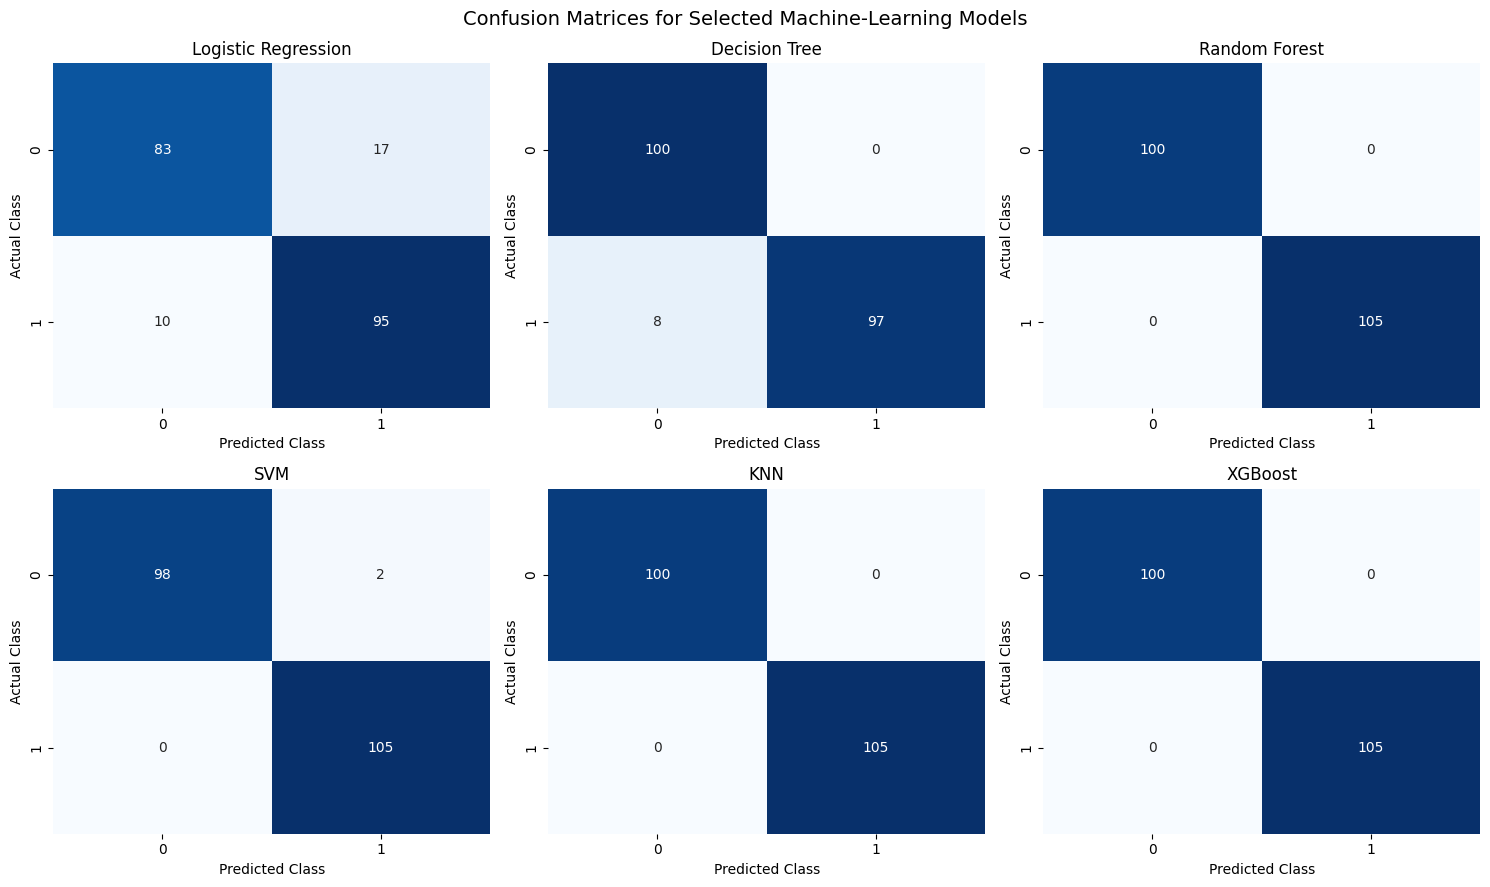

In [37]:
# Compare classification errors across all tuned models in a single figure
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()

for ax, name in zip(axes, best_models):

    # Calculate the confusion matrix for the current model
    cm = confusion_matrix(
        y_test,
        test_predictions[name]
    )

    # Display the classification outcomes for each target class
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

# Provide a common title for the model comparison
plt.suptitle(
    "Confusion Matrices for Selected Machine-Learning Models",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [38]:
confusion_summary = []

for name in best_models:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_predictions[name]
    ).ravel()

    confusion_summary.append({
        "Model": name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

confusion_df = pd.DataFrame(confusion_summary)

display(confusion_df)

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,83,17,10,95
1,Decision Tree,100,0,8,97
2,Random Forest,100,0,0,105
3,SVM,98,2,0,105
4,KNN,100,0,0,105
5,XGBoost,100,0,0,105


## ROC Curve Comparison

ROC curves compare the ability of each model to distinguish between the two target classes across classification thresholds. ROC-AUC summarises discrimination, while the curves provide a visual comparison of model behaviour beyond a single selected threshold.

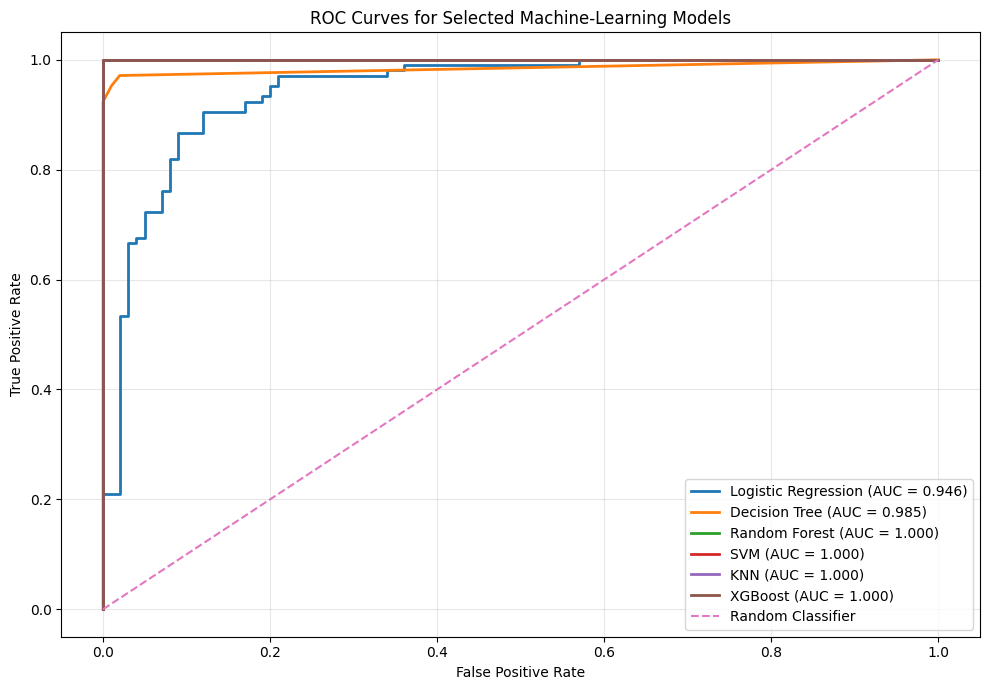

In [39]:
# Compare the discrimination performance of all tuned models using ROC curves
plt.figure(figsize=(10, 7))

for name in best_models:

    # Calculate the false-positive and true-positive rates across thresholds
    fpr, tpr, _ = roc_curve(
        y_test,
        test_probabilities[name]
    )

    # Calculate the area under the ROC curve for the current model
    auc_score = roc_auc_score(
        y_test,
        test_probabilities[name]
    )

    # Plot the ROC curve with its corresponding AUC value
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Add the reference line representing random classification
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Selected Machine-Learning Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Multi-Metric Performance Comparison

A multi-metric comparison is presented because no single measure adequately represents medical classification performance. The visual comparison supports RQ2 by showing how each algorithm performs across accuracy, precision, sensitivity, specificity, F1-score and ROC-AUC.

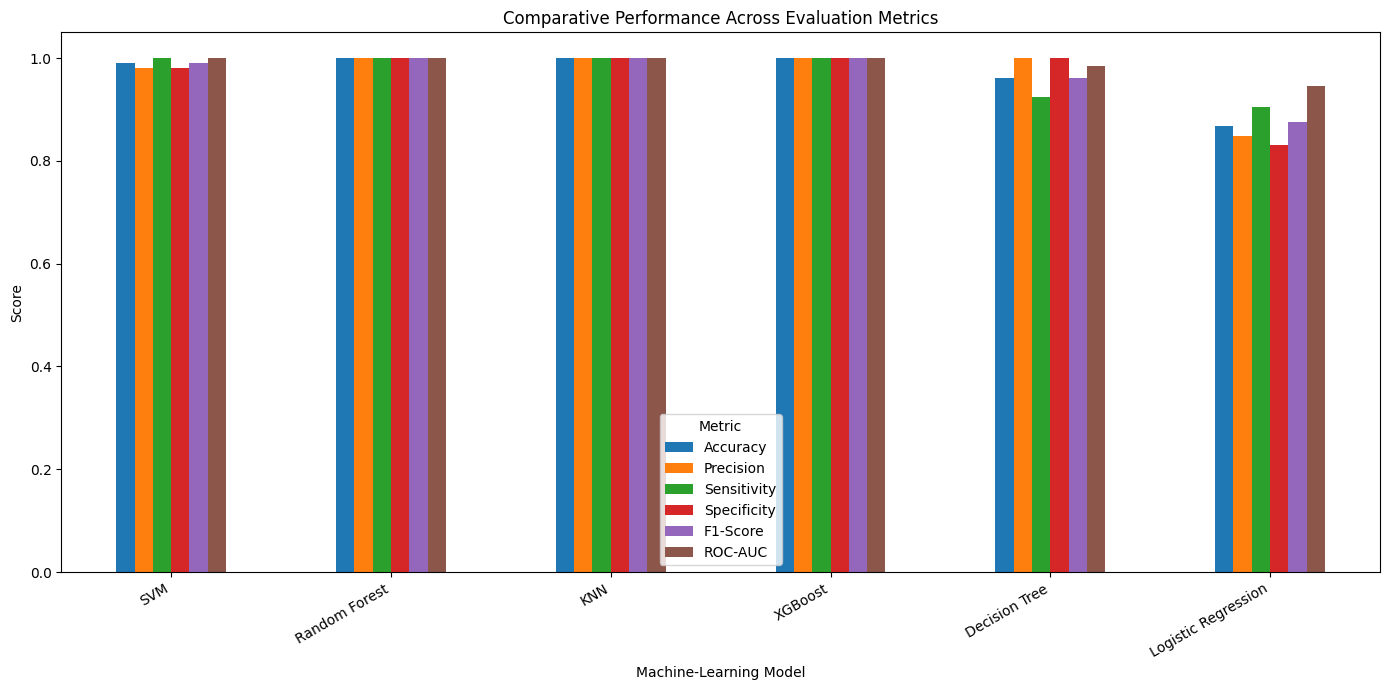

In [40]:
# Prepare the evaluation metrics for visual comparison across models
plot_df = results_df.set_index("Model")[metric_columns]

# Create a grouped bar chart to compare the selected performance measures
ax = plot_df.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparative Performance Across Evaluation Metrics")
plt.xlabel("Machine-Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## Multi-Metric Comparative Ranking

To address RQ2 transparently, each model is ranked across the six predefined metrics, with rank one representing the highest observed value for each metric. The mean rank provides a descriptive overall comparison without treating any single performance measure as sufficient.

In [41]:
# Create a separate table for comparing model rankings across evaluation metrics
ranking_df = results_df.copy()

for metric in metric_columns:

    # Assign a rank to each model based on its performance for the current metric
    ranking_df[f"{metric} Rank"] = (
        ranking_df[metric]
        .rank(
            ascending=False,
            method="min"
        )
    )

# Identify the ranking columns used for the overall comparison
rank_columns = [
    f"{metric} Rank"
    for metric in metric_columns
]

# Calculate the mean rank across all selected evaluation metrics
ranking_df["Mean Rank"] = ranking_df[rank_columns].mean(axis=1)

# Order models by their mean rank for comparative assessment
ranking_df = ranking_df.sort_values(
    "Mean Rank",
    ascending=True
).reset_index(drop=True)

# Display the metric-specific and mean ranking results
display(
    ranking_df[
        ["Model"] + rank_columns + ["Mean Rank"]
    ].round(3)
)

,Model,Accuracy Rank,Precision Rank,Sensitivity Rank,Specificity Rank,F1-Score Rank,ROC-AUC Rank,Mean Rank
0,Random Forest,1.0,1.0,1.0,1.0,1.0,1.0,1.000
1,KNN,1.0,1.0,1.0,1.0,1.0,1.0,1.000
2,XGBoost,1.0,1.0,1.0,1.0,1.0,1.0,1.000
3,SVM,4.0,5.0,1.0,5.0,4.0,1.0,3.333
4,Decision Tree,5.0,1.0,5.0,1.0,5.0,5.0,3.667
5,Logistic Regression,6.0,6.0,6.0,6.0,6.0,6.0,6.000


In [42]:
rq2_summary = ranking_df[
    ["Model", "Mean Rank"]
].copy()

rq2_summary["Mean Rank"] = rq2_summary["Mean Rank"].round(3)

display(rq2_summary)

,Model,Mean Rank
0,Random Forest,1.000
1,KNN,1.000
2,XGBoost,1.000
3,SVM,3.333
4,Decision Tree,3.667
5,Logistic Regression,6.000


##  Metric-Specific Performance

Metric-specific leaders are identified to demonstrate whether the comparative results are consistent or involve trade-offs. This is important because a model may achieve the highest sensitivity while another achieves higher specificity or precision, preventing a simplistic interpretation of overall performance.

In [43]:
# Identify the model associated with the highest observed score for each metric
metric_leaders = []

for metric in metric_columns:

    # Locate the model with the highest value for the current evaluation metric
    best_index = results_df[metric].idxmax()

    metric_leaders.append({
        "Metric": metric,
        "Model": results_df.loc[best_index, "Model"],
        "Score": results_df.loc[best_index, metric]
    })

# Convert the metric-level comparison into a structured results table
metric_leaders_df = pd.DataFrame(metric_leaders)

# Display the highest observed score for each evaluation metric
display(metric_leaders_df.round(4))

,Metric,Model,Score
0,Accuracy,Random Forest,1.0
1,Precision,Random Forest,1.0
2,Sensitivity,SVM,1.0
3,Specificity,Random Forest,1.0
4,F1-Score,Random Forest,1.0
5,ROC-AUC,SVM,1.0


## Sensitivity-Specificity Trade-Off

Sensitivity and specificity are examined together because heart-disease classification involves competing error types. High sensitivity reduces false negatives, whereas high specificity reduces false positives. Their joint interpretation provides a more clinically meaningful assessment than either metric considered independently.

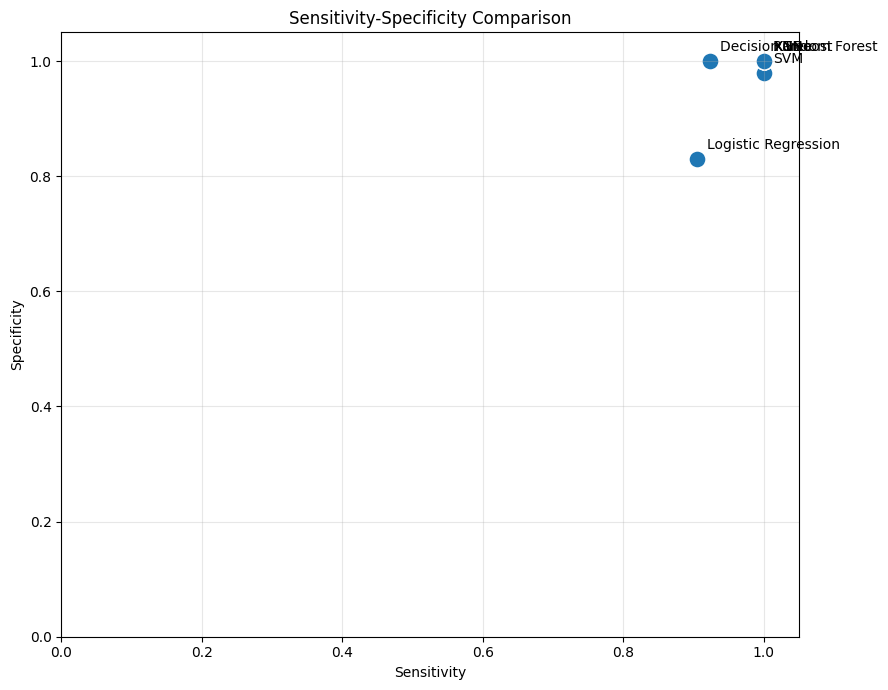

In [44]:
# Visualise the trade-off between sensitivity and specificity across models
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=results_df,
    x="Sensitivity",
    y="Specificity",
    s=150
)

for _, row in results_df.iterrows():

    # Label each point with the corresponding model name
    plt.annotate(
        row["Model"],
        (
            row["Sensitivity"],
            row["Specificity"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

# Use a common scale to support direct comparison of both metrics
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)

plt.xlabel("Sensitivity")
plt.ylabel("Specificity")
plt.title("Sensitivity-Specificity Comparison")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##  Model Complexity and Practical Characteristics

Predictive performance alone does not establish practical suitability. The models are therefore considered according to interpretability, preprocessing requirements, computational characteristics and modelling complexity. This analysis supports RQ3 while distinguishing computational evidence from clinical validation.

In [45]:
# Summarise key methodological characteristics of the selected classification models
model_characteristics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN",
        "XGBoost"
    ],

    "Model Family": [
        "Linear statistical classifier",
        "Tree-based classifier",
        "Bagging ensemble",
        "Margin-based classifier",
        "Distance-based classifier",
        "Boosting ensemble"
    ],

    "Interpretability": [
        "High",
        "High",
        "Moderate",
        "Low",
        "Moderate",
        "Low"
    ],

    "Scaling Required": [
        "Yes",
        "Not essential",
        "Not essential",
        "Yes",
        "Yes",
        "Not essential"
    ]
})

# Display the model characteristics for methodological comparison
display(model_characteristics)

,Model,Model Family,Interpretability,Scaling Required
0,Logistic Regression,Linear statistical classifier,High,Yes
1,Decision Tree,Tree-based classifier,High,Not essential
2,Random Forest,Bagging ensemble,Moderate,Not essential
3,SVM,Margin-based classifier,Low,Yes
4,KNN,Distance-based classifier,Moderate,Yes
5,XGBoost,Boosting ensemble,Low,Not essential


## Computational Cost

Training time is recorded as an additional practical consideration. Computational cost does not determine medical suitability, but it provides supporting evidence about the relative implementation requirements of the selected algorithms and contributes to the technical evaluation of the artefact.

In [46]:
training_time_df = cv_summary[
    ["Training Time (seconds)"]
].sort_values(
    "Training Time (seconds)"
)

display(training_time_df.round(3))

,Training Time (seconds)
KNN,2.199
Decision Tree,3.803
Logistic Regression,3.844
SVM,6.102
XGBoost,7.595
Random Forest,35.994


## Random Forest Feature Importance

Feature importance is examined to provide an interpretable view of the Random Forest model. These values indicate the relative contribution of transformed predictors to model splitting behaviour and should be interpreted as model-specific associations rather than causal clinical effects.

,Feature,Importance
7,categorical__cp_0,0.094379
4,numeric__oldpeak,0.091564
3,numeric__thalach,0.089939
28,categorical__thal_2,0.088153
0,numeric__age,0.078956
2,numeric__chol,0.068414
21,categorical__ca_0,0.066237
29,categorical__thal_3,0.057012
1,numeric__trestbps,0.054864
16,categorical__exang_0,0.042422


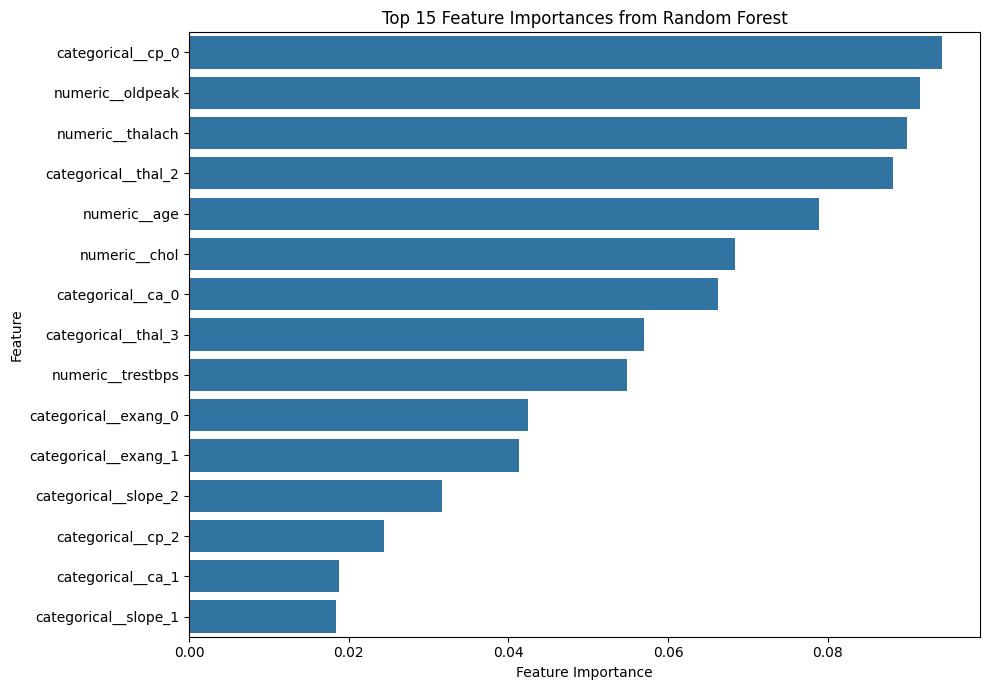

In [47]:
# Extract the fitted Random Forest pipeline and its individual components
rf_model = best_models["Random Forest"]

rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["model"]

# Retrieve the feature names generated by the preprocessing pipeline
feature_names = rf_preprocessor.get_feature_names_out()

# Combine transformed feature names with their Random Forest importance scores
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Order features from highest to lowest importance
rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

# Display the 15 most influential features
display(rf_importance.head(15))

# Visualise the relative importance of the 15 leading features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances from Random Forest")
plt.tight_layout()
plt.show()

## Logistic Regression Coefficients

Logistic Regression provides a comparatively interpretable baseline because coefficients indicate the direction of association between transformed predictors and the predicted log-odds. Coefficients are interpreted cautiously because association within this dataset does not establish clinical causation.

In [48]:
lr_model = best_models["Logistic Regression"]

lr_preprocessor = lr_model.named_steps["preprocessor"]
lr_classifier = lr_model.named_steps["model"]

lr_feature_names = lr_preprocessor.get_feature_names_out()

lr_coefficients = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_classifier.coef_[0],
    "Absolute Coefficient": np.abs(lr_classifier.coef_[0])
})

lr_coefficients = lr_coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(lr_coefficients.head(15))

,Feature,Coefficient,Absolute Coefficient
25,categorical__ca_4,2.896092,2.896092
23,categorical__ca_2,-2.386249,2.386249
26,categorical__thal_0,-1.431919,1.431919
7,categorical__cp_0,-1.319334,1.319334
21,categorical__ca_0,1.248439,1.248439
27,categorical__thal_1,1.005651,1.005651
22,categorical__ca_1,-0.958327,0.958327
6,categorical__sex_1,-0.957796,0.957796
10,categorical__cp_3,0.950216,0.950216
5,categorical__sex_0,0.912131,0.912131


## Model-Specific Permutation Importance

Permutation importance is calculated for the model with the strongest descriptive multi-metric ranking. The method evaluates how prediction performance changes when individual original features are randomly permuted, supporting interpretation without using importance as evidence of causality.

Model selected for permutation analysis:
Random Forest


,Feature,Importance Mean,Importance Std
11,ca,0.027686,0.005700
12,thal,0.025271,0.005256
2,cp,0.014993,0.003282
8,exang,0.002295,0.001154
9,oldpeak,0.001540,0.000842
10,slope,0.001024,0.000611
1,sex,0.000926,0.000673
3,trestbps,0.000212,0.000113
7,thalach,0.000033,0.000057
0,age,0.000017,0.000035


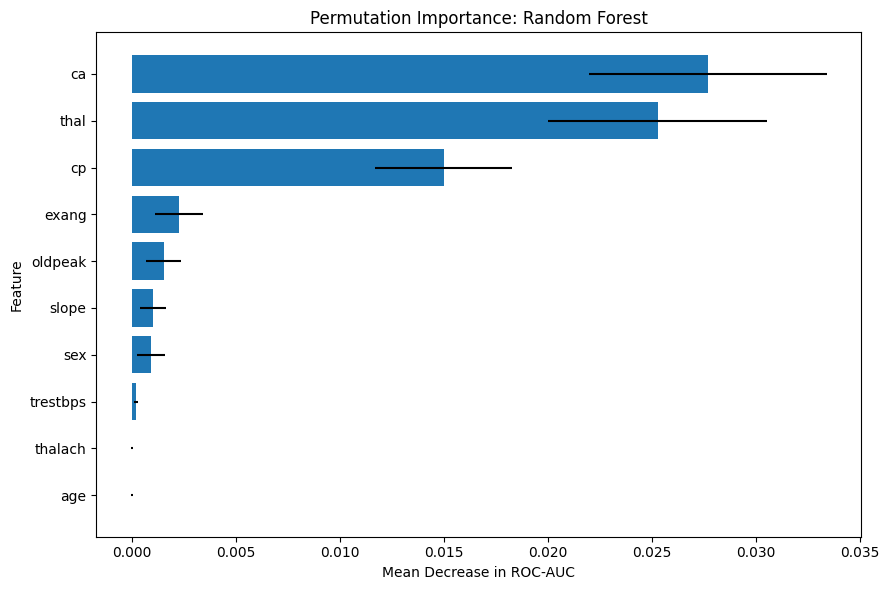

In [49]:
# Select the highest-ranked model for permutation-based feature analysis
top_ranked_model_name = ranking_df.iloc[0]["Model"]
top_ranked_model = best_models[top_ranked_model_name]

print("Model selected for permutation analysis:")
print(top_ranked_model_name)

# Estimate feature importance by measuring the reduction in ROC-AUC after permutation
permutation_result = permutation_importance(
    top_ranked_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Organise permutation results for comparison and visualisation
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

# Rank features according to their mean permutation importance
permutation_df = permutation_df.sort_values(
    "Importance Mean",
    ascending=False
)

# Display the complete permutation-importance results
display(permutation_df)

# Select the ten most influential features for visual comparison
top_permutation = permutation_df.head(10).sort_values(
    "Importance Mean",
    ascending=True
)

# Plot mean ROC-AUC reduction with variability across permutations
plt.figure(figsize=(9, 6))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance Mean"],
    xerr=top_permutation["Importance Std"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title(
    f"Permutation Importance: {top_ranked_model_name}"
)

plt.tight_layout()
plt.show()

## Training-Test Performance Comparison

Potential overfitting is assessed by comparing training and independent test performance. A substantial performance gap may indicate that a model has learned patterns specific to the training observations rather than generalisable relationships.

In [50]:
overfitting_results = []

for name, model in best_models.items():

    train_probability = model.predict_proba(X_train)[:, 1]
    test_probability = test_probabilities[name]

    train_auc = roc_auc_score(
        y_train,
        train_probability
    )

    test_auc = roc_auc_score(
        y_test,
        test_probability
    )

    overfitting_results.append({
        "Model": name,
        "Training ROC-AUC": train_auc,
        "Test ROC-AUC": test_auc,
        "AUC Gap": train_auc - test_auc
    })

overfitting_df = pd.DataFrame(
    overfitting_results
).sort_values(
    "AUC Gap",
    ascending=False
)

display(overfitting_df.round(4))

,Model,Training ROC-AUC,Test ROC-AUC,AUC Gap
1,Decision Tree,1.0000,0.9850,0.0150
2,Random Forest,1.0000,1.0000,0.0000
4,KNN,1.0000,1.0000,0.0000
3,SVM,1.0000,1.0000,0.0000
5,XGBoost,1.0000,1.0000,0.0000
0,Logistic Regression,0.9452,0.9457,-0.0005


## Cross-Validation Stability

Model stability is examined through the variability of cross-validation performance. Stable performance across folds provides stronger evidence of generalisation within the available dataset, although it cannot replace external validation using an independent clinical population.

In [51]:
cv_stability_results = []

for name, model in best_models.items():

    # Use the already selected model and evaluate it using
    # stratified cross-validation on the training data.
    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        scoring="roc_auc",
        cv=cv_strategy,
        n_jobs=-1
    )

    cv_stability_results.append({
        "Model": name,
        "Mean CV ROC-AUC": scores.mean(),
        "Std CV ROC-AUC": scores.std(),
        "Minimum CV ROC-AUC": scores.min(),
        "Maximum CV ROC-AUC": scores.max()
    })

cv_stability_df = pd.DataFrame(
    cv_stability_results
).sort_values(
    "Mean CV ROC-AUC",
    ascending=False
)

display(cv_stability_df.round(4))

,Model,Mean CV ROC-AUC,Std CV ROC-AUC,Minimum CV ROC-AUC,Maximum CV ROC-AUC
4,KNN,0.9996,0.0006,0.9985,1.0000
2,Random Forest,0.9986,0.0015,0.9964,1.0000
5,XGBoost,0.9957,0.0051,0.9863,1.0000
3,SVM,0.9928,0.0056,0.9869,1.0000
1,Decision Tree,0.9773,0.0052,0.9729,0.9875
0,Logistic Regression,0.9369,0.0095,0.9254,0.9524


## Consolidated Experimental Results

The final results combine independent test performance, cross-validation evidence and computational information. This consolidated view supports transparent comparison and provides the principal quantitative evidence for answering the first two research questions.

In [52]:
# Combine test-set performance, cross-validation stability and training time
final_results = results_df.merge(
    cv_stability_df[
        [
            "Model",
            "Mean CV ROC-AUC",
            "Std CV ROC-AUC"
        ]
    ],
    on="Model",
    how="left"
)

# Add the recorded training time for each tuned model
final_results = final_results.merge(
    cv_summary.reset_index().rename(
        columns={"index": "Model"}
    )[
        [
            "Model",
            "Training Time (seconds)"
        ]
    ],
    on="Model",
    how="left"
)

# Order models by test-set ROC-AUC for the final comparative table
final_results = final_results.sort_values(
    "ROC-AUC",
    ascending=False
)

# Display the consolidated model evaluation results
display(final_results.round(4))

,Model,Accuracy,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC,Mean CV ROC-AUC,Std CV ROC-AUC,Training Time (seconds)
0,SVM,0.9902,0.9813,1.0000,0.98,0.9906,1.0000,0.9928,0.0056,6.1018
1,Random Forest,1.0000,1.0000,1.0000,1.00,1.0000,1.0000,0.9986,0.0015,35.9937
2,KNN,1.0000,1.0000,1.0000,1.00,1.0000,1.0000,0.9996,0.0006,2.1988
3,XGBoost,1.0000,1.0000,1.0000,1.00,1.0000,1.0000,0.9957,0.0051,7.5954
4,Decision Tree,0.9610,1.0000,0.9238,1.00,0.9604,0.9850,0.9773,0.0052,3.8025
5,Logistic Regression,0.8683,0.8482,0.9048,0.83,0.8756,0.9457,0.9369,0.0095,3.8443
